# MMP13-OA validation — Independent validation of the MMP13 programme
**Design (pre-specified).** The discovery signature is *locked* from MMP13-OA discovery analysis
(`mmp13_oa/02_tables_v5/T3_MMP13_coexpression_consensus.csv`): the top 150 positive and top 150 negative robust MMP13
partners and the genome-wide meta ρ. Nothing from the validation data is used to choose genes.

| Module | Data | Test |
|---|---|---|
| **V1 · Held-out bulk** | GEO series **not used in discovery** (cartilage RNA-seq GSE114007; synovium GSE82107, GSE89408) | Within-OA correlation with MMP13: genome-wide concordance with discovery, enrichment of locked partners, module score ~ MMP13 |
| **V2 · OA vs control (held-out)** | same | Is MMP13 higher in OA, and does age (if annotated) explain it? |
| **V3 · Single cell** | OA cartilage scRNA-seq (default GSE104782) | Which cell clusters carry the MMP13 module? Marker genes reported as found (no assumed labels) |

Each dataset's structure (files, columns, groups) is printed so it can be checked; a dataset that cannot be parsed is
reported and skipped, never guessed.

Outputs → `MyDrive/mmp13_oa/05_validation/`.

In [1]:
# [step-0-install]
!pip -q install GEOparse gseapy scanpy leidenalg igraph mygene openpyxl
!apt-get -qq install -y fonts-liberation > /dev/null 2>&1 || true

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.7/689.7 kB 24.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 53.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 45.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 41.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.1/52.1 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 44.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 M

In [2]:
# [step-0-setup]
import os, re, io, gzip, json, tarfile, zipfile, shutil, warnings, datetime, urllib.request
warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/mmp13_oa"
except ImportError:
    BASE = os.path.abspath("./mmp13_oa")
VDIR = {k: os.path.join(BASE, "05_validation", v) for k, v in
        {"cache": "cache", "tables": "tables", "figs": "figures", "src": "figures/source_data"}.items()}
for d in VDIR.values():
    os.makedirs(d, exist_ok=True)
GEO_CACHE = os.path.join(BASE, "00_geo_cache"); os.makedirs(GEO_CACHE, exist_ok=True)
DISCOVERY = os.path.join(BASE, "02_tables_v5", "T3_MMP13_coexpression_consensus.csv")
assert os.path.exists(DISCOVERY), f"Discovery table not found: {DISCOVERY} — run MMP13-OA discovery analysis first."
RUN = datetime.datetime.now().strftime("%Y-%m-%d %H:%M")
print("Validation outputs →", os.path.join(BASE, "05_validation"))

Mounted at /content/drive
Validation outputs → /content/drive/MyDrive/mmp13_oa/05_validation


## 1 · Configuration

In [3]:
# [step-1-config]
TARGET = "MMP13"
N_TOP = 150           # locked partner set size (same as discovery enrichment)
N_MODULE = 50         # module score size (same as discovery paired analysis)
MIN_OA = 8

BULK = {
    # accession: tissue, kind ('matrix' = series-matrix values; 'supp' = supplementary expression table), expected design
    "GSE114007": dict(tissue="Cartilage", kind="supp", expect="18 normal vs 20 OA (Fisch et al., 2018)", n=dict(OA=20, Control=18), use=True),
    "GSE82107":  dict(tissue="Synovium",  kind="matrix", expect="OA vs normal synovium", n=dict(OA=10, Control=7), use=True),
    "GSE89408":  dict(tissue="Synovium",  kind="supp", expect="OA vs normal synovium (+RA, arthralgia excluded)", use=True),
}
SC = dict(acc="GSE104782", expect="OA knee cartilage chondrocytes (Ji et al., 2019)", use=True)

EXCLUDE_RE = r"rheumat|\bra\b|arthralgia|undifferentiated|early arthritis|\bua\b"
CTRL_RE = (r"healthy|non[- ]?oa\b|non[- ]?osteoarthrit|\bcontrol|post[- ]?mortem|normal|donor|"
           r"arthroscopic partial meniscectomy")
OA_RE = r"osteoarthrit|(?<![a-z0-9])oa(?![a-z0-9])"   # "oa_cart_1" counts; "goal" does not
GRADE_RE = r"\b(oa|kl|kellgren[- ]?lawrence|outerbridge|mankin|icrs)[ _-]*(grade|score|stage)\s*[:=]?\s*\S*"
HYPERTROPHY = ["RUNX2", "COL10A1", "IHH", "ALPL", "VEGFA", "SPP1", "PTH1R"]
SEED = 7

## 2 · Locked discovery signature

In [4]:
# [step-2-signature]
import numpy as np, pandas as pd
from scipy import stats
D = pd.read_csv(DISCOVERY, index_col=0)
rob = D[(D.FDR < 0.05) & (D.sign_consistency >= 0.75)]
SIG_POS = list(rob[rob.meta_rho > 0].sort_values("meta_z", ascending=False).index[:N_TOP])
SIG_NEG = list(rob[rob.meta_rho < 0].sort_values("meta_z").index[:N_TOP])
MOD_POS, MOD_NEG = SIG_POS[:N_MODULE], SIG_NEG[:N_MODULE]
json.dump(dict(locked=RUN, source=DISCOVERY, pos=SIG_POS, neg=SIG_NEG),
          open(os.path.join(VDIR["tables"], "V0_locked_signature.json"), "w"), indent=1)
print(f"Locked signature: {len(SIG_POS)} positive, {len(SIG_NEG)} negative partners "
      f"(top positive: {', '.join(SIG_POS[:8])})")

Locked signature: 150 positive, 150 negative partners (top positive: OLFML2B, THY1, THBS2, GJA1, COL5A2, AEBP1, MMP9, FAT1)


## 3 · Loaders (series matrix and supplementary tables)

In [5]:
# [step-3-loaders]
import GEOparse

def _symbol_column(tbl):
    for c in ["Gene Symbol", "GENE_SYMBOL", "Symbol", "ILMN_Gene", "gene_symbol", "GENE", "Gene symbol", "SYMBOL",
              "gene_assignment"]:
        if c in tbl.columns and tbl[c].notna().mean() > 0.3:
            return c
    for c in tbl.columns:
        if "symbol" in c.lower():
            return c
    raise ValueError("no gene-symbol column")

def _clean(s, col):
    if not isinstance(s, str) or not s.strip(): return np.nan
    if col == "gene_assignment":
        p = s.split("//"); return p[1].strip() if len(p) > 1 else np.nan
    return re.split(r"\s*///\s*|\s*//\s*|;|,", s)[0].strip() or np.nan

def sample_table(gse):
    rows = {}
    for k, g in gse.gsms.items():
        md = g.metadata
        txt = " | ".join(md.get("title", []) + md.get("source_name_ch1", []) + md.get("characteristics_ch1", [])).lower()
        age = None
        for ch in md.get("characteristics_ch1", []):
            m = re.match(r"\s*age[^:]*:\s*([\d.]+)", ch.lower())
            if m: age = float(m.group(1))
        aliases = [d_.strip() for d_ in md.get("description", []) if d_.strip()] + \
                  [ch.split(":", 1)[1].strip() for ch in md.get("characteristics_ch1", []) if ":" in ch]
        rows[k] = dict(title=md.get("title", [""])[0], text=txt, age=age, platform=md.get("platform_id", [""])[0],
                       aliases=aliases)
    return pd.DataFrame.from_dict(rows, orient="index")

def classify(t):
    t = re.sub(GRADE_RE, " ", t)      # "oa grade: 1" is a severity field, not a diagnosis
    if re.search(EXCLUDE_RE, t): return None
    if re.search(r"non[- ]?oa\b|non[- ]?osteoarthrit|without oa", t): return "Control"
    if re.search(OA_RE, t): return "OA"
    if re.search(CTRL_RE, t): return "Control"
    return None

def collapse(expr, sym):
    expr = expr.join(sym.rename("SYMBOL"), how="inner").dropna(subset=["SYMBOL"])
    v = expr.drop(columns="SYMBOL"); v["SYMBOL"] = expr["SYMBOL"]
    v["_m"] = v.drop(columns="SYMBOL").mean(axis=1)
    return v.sort_values("_m", ascending=False).drop_duplicates("SYMBOL").drop(columns="_m").set_index("SYMBOL")

def to_log(expr):
    x = expr.astype(float)
    if np.nanpercentile(x.values, 99) > 50:
        integer_like = np.nanmean(np.isclose(x.values[~np.isnan(x.values)][:200000] % 1, 0)) > 0.95
        if integer_like:                                  # raw counts → log2 CPM
            x = np.log2(x / x.sum(axis=0) * 1e6 + 1)
        else:
            x = np.log2(x.clip(lower=0) + 1)
    return x

def https(url):
    return url.replace("ftp://ftp.ncbi.nlm.nih.gov", "https://ftp.ncbi.nlm.nih.gov")

def fetch(url, dest_dir):
    os.makedirs(dest_dir, exist_ok=True)
    fn = os.path.join(dest_dir, os.path.basename(url))
    if not os.path.exists(fn):
        urllib.request.urlretrieve(https(url), fn)
    return fn

def read_table_any(fn):
    low = fn.lower()
    if low.endswith((".xlsx", ".xls")):
        return pd.read_excel(fn)
    opener = gzip.open if low.endswith(".gz") else open
    with opener(fn, "rt", errors="replace") as fh:
        head = fh.read(20000)
    sep = "\t" if head.count("\t") > head.count(",") else ","
    return pd.read_csv(fn, sep=sep, compression="infer", low_memory=False)

def map_symbols(index):
    idx = pd.Index(index.astype(str))
    if idx.str.match(r"^ENSG\d+").mean() > 0.5:
        import mygene
        ids = idx.str.replace(r"\..*$", "", regex=True)
        res = mygene.MyGeneInfo().querymany(list(ids.unique()), scopes="ensembl.gene", fields="symbol",
                                            species="human", as_dataframe=True, verbose=False)
        mp = res["symbol"].dropna()
        mp = mp[~mp.index.duplicated()]
        return pd.Series(ids.map(mp).values, index=index), "Ensembl→symbol via MyGene.info"
    return pd.Series(idx.values, index=index), "symbols as provided"

def load_matrix(acc):
    gse = GEOparse.get_GEO(geo=acc, destdir=GEO_CACHE, silent=True)
    st = sample_table(gse)
    gpl = list(gse.gpls)[0]
    gsms = {k: v for k, v in gse.gsms.items() if v.metadata.get("platform_id", [gpl])[0] == gpl}
    expr = pd.concat({k: g.table.set_index("ID_REF")["VALUE"] for k, g in gsms.items()}, axis=1)
    expr = expr.apply(pd.to_numeric, errors="coerce")
    ann = gse.gpls[gpl].table; col = _symbol_column(ann)
    sym = ann.set_index("ID")[col].map(lambda s: _clean(s, col))
    expr.index = expr.index.astype(str); sym.index = sym.index.astype(str)
    expr = collapse(expr, sym)
    expr = to_log(expr).dropna(how="any")
    return expr, st.loc[expr.columns], gse.metadata.get("title", [""])[0], f"series matrix ({gpl})"

def load_supp(acc):
    gse = GEOparse.get_GEO(geo=acc, destdir=GEO_CACHE, silent=True)
    st = sample_table(gse)
    files = [f for f in gse.metadata.get("supplementary_file", []) if not f.lower().endswith((".tar", "filelist.txt"))]
    print(f"   supplementary files: {[os.path.basename(f) for f in gse.metadata.get('supplementary_file', [])]}")
    if not files:
        raise ValueError("no series-level supplementary expression table")
    parts, notes = [], []
    keys = {}
    for k_, r_ in st.iterrows():
        for v_ in [k_, r_["title"]] + r_.get("aliases", []):
            if isinstance(v_, str) and v_.strip(): keys.setdefault(v_.lower().strip(), set()).add(k_)
    for f in files:
        fn = fetch(f, os.path.join(VDIR["cache"], acc))
        try:
            t = read_table_any(fn)
        except Exception as e:
            print(f"   could not read {os.path.basename(fn)}: {e}"); continue
        gene_col = next((c for c in t.columns if not pd.api.types.is_numeric_dtype(t[c])), None)
        if gene_col is None: continue
        t = t.set_index(gene_col); num = t.select_dtypes(include=[np.number])
        if num.shape[1] < 3: continue
        cols = pd.Index(num.columns.astype(str)); mapped = {}
        for c in cols:
            cl = c.lower().strip()
            hit = keys.get(cl, set())
            if not hit:
                hit = {g for kk, gs in keys.items() for g in gs
                       if re.search(rf"(^|[_\s.\-|]){re.escape(cl)}($|[_\s.\-|])", kk)}
            if len(hit) == 1: mapped[c] = next(iter(hit))
        print(f"   {os.path.basename(fn)}: {len(mapped)}/{len(cols)} columns matched to GEO samples "
              f"(columns e.g. {list(cols[:4])}; titles e.g. {list(st['title'][:4])})")
        if len(mapped) >= 0.5 * len(cols):
            parts.append(num[list(mapped)].rename(columns=mapped)); notes.append(os.path.basename(fn))
    if not parts:
        raise ValueError("no supplementary table whose columns match the GEO samples — see printout")
    best = pd.concat([p.groupby(level=0).sum() if p.index.duplicated().any() else p for p in parts], axis=1, join="inner")
    best = best.loc[:, ~best.columns.duplicated()]
    note = " + ".join(notes)
    best = best.groupby(level=0).sum() if best.index.duplicated().any() else best
    sym, how = map_symbols(best.index)
    best.index = best.index.astype(str); sym.index = sym.index.astype(str)
    expr = collapse(best, sym)
    expr = to_log(expr).dropna(how="any")
    return expr, st.loc[expr.columns], gse.metadata.get("title", [""])[0], f"{note}; {how}"

## 4 · V1–V2 · Held-out bulk validation (Figure V1, Table V1–V2)


=== GSE114007 (Cartilage) — expected: 18 normal vs 20 OA (Fisch et al., 2018)
   supplementary files: ['GSE114007_OA_normalized.counts.txt.gz', 'GSE114007_normal_normalized.counts.txt.gz', 'GSE114007_raw_counts.xlsx']
   GSE114007_OA_normalized.counts.txt.gz: 20/22 columns matched to GEO samples (columns e.g. ['OA_Cart_1_7', 'OA_Cart_10_9', 'OA_Cart_2_8', 'OA_Cart_3_9']; titles e.g. ['Normal_Cart_2_2', 'Normal_Cart_3_3', 'Normal_Cart_4_4', 'Normal_Cart_5_5'])
   GSE114007_normal_normalized.counts.txt.gz: 18/20 columns matched to GEO samples (columns e.g. ['Normal_Cart_10_8', 'Normal_Cart_2_2', 'Normal_Cart_3_3', 'Normal_Cart_4_4']; titles e.g. ['Normal_Cart_2_2', 'Normal_Cart_3_3', 'Normal_Cart_4_4', 'Normal_Cart_5_5'])
   GSE114007_raw_counts.xlsx: 18/18 columns matched to GEO samples (columns e.g. ['Normal_Cart_10_8', 'Normal_Cart_2_2', 'Normal_Cart_3_3', 'Normal_Cart_4_4']; titles e.g. ['Normal_Cart_2_2', 'Normal_Cart_3_3', 'Normal_Cart_4_4', 'Normal_Cart_5_5'])
   title: Identific

saved FigureV1_heldout_replication


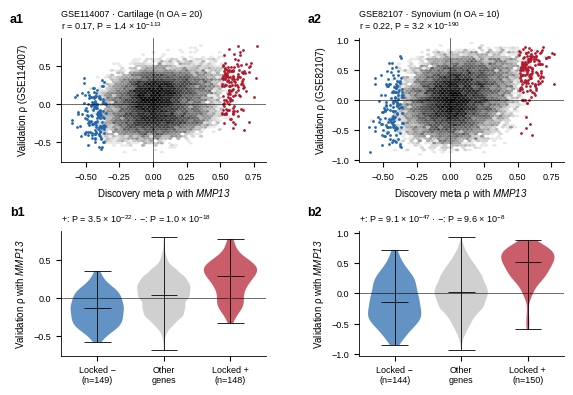

In [6]:
# [module-V1]
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib import font_manager
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
_av = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"] if f in _av), "DejaVu Sans")
mpl.rcParams.update({"font.family": "sans-serif", "font.sans-serif": [FONT], "font.size": 7, "axes.labelsize": 7,
                     "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6.5, "legend.frameon": False,
                     "axes.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42,
                     "savefig.dpi": 300, "savefig.bbox": "tight", "mathtext.fontset": "custom", "mathtext.rm": FONT,
                     "mathtext.it": f"{FONT}:italic", "mathtext.sf": f"{FONT}:italic"})
MM = 1 / 25.4; W2 = 183 * MM
POS_COL, NEG_COL, BG_COL = "#B2182B", "#2166AC", "#BDBDBD"
def it(g): return "$\\mathsf{" + g + "}$"
def save(fig, name, source=None):
    b = os.path.join(VDIR["figs"], name)
    fig.savefig(b + ".png", dpi=300); fig.savefig(b + ".tiff", dpi=300, pil_kwargs={"compression": "tiff_lzw"})
    fig.savefig(b + ".pdf")
    if source is not None: source.to_csv(os.path.join(VDIR["src"], name + "_source_data.csv"))
    print("saved", name)
def fp(p):
    if p is None or np.isnan(p): return "n/a"
    if p < 0.001:
        m, e = f"{p:.1e}".split("e"); return f"{m} × 10$^{{{int(e)}}}$"
    return f"{p:.3f}" if p < 0.01 else f"{p:.2f}"
def zrows(df): return df.sub(df.mean(axis=1), axis=0).div(df.std(axis=1).replace(0, np.nan), axis=0)
def spearman_vs(expr, vec):
    R = expr.rank(axis=1).values; v = stats.rankdata(vec)
    R = R - R.mean(axis=1, keepdims=True); v = v - v.mean()
    den = np.sqrt((R ** 2).sum(axis=1) * (v ** 2).sum())
    return pd.Series((R @ v) / np.where(den == 0, np.nan, den), index=expr.index)

VAL, ROWS = {}, []
for acc, cfg in BULK.items():
    if not cfg["use"]: continue
    print(f"\n=== {acc} ({cfg['tissue']}) — expected: {cfg['expect']}")
    try:
        expr, st, title, how = (load_matrix if cfg["kind"] == "matrix" else load_supp)(acc)
        st["group"] = st["text"].map(classify)
        print(f"   title: {title}\n   source: {how}")
        print("   groups:", st["group"].value_counts(dropna=False).to_dict())
        if cfg.get("n"):
            got = {g_: int((st.loc[st.index.intersection(expr.columns), "group"] == g_).sum()) for g_ in cfg["n"]}
            if got != cfg["n"]:
                raise ValueError(f"group sizes {got} do not match the published design {cfg['n']} — not used")
        for g_ in ["OA", "Control"]:
            ex = st[st.group == g_]["text"].head(1)
            if len(ex): print(f"   e.g. {g_}: {ex.iloc[0][:120]}")
        un = st[st.group.isna()]["text"].head(2)
        for u in un: print(f"   unassigned e.g.: {u[:120]}")
        st.drop(columns=["aliases"], errors="ignore").to_csv(os.path.join(VDIR["tables"], f"{acc}_groups.csv"))
        if TARGET not in expr.index: raise ValueError("MMP13 not measured")
        VAL[acc] = dict(expr=expr, st=st, tissue=cfg["tissue"], title=title)
    except Exception as e:
        print(f"   SKIPPED: {type(e).__name__}: {e}")
        ROWS.append(dict(dataset=acc, tissue=cfg["tissue"], status=f"skipped: {e}"))

RES, CORR = [], {}
for acc, v in VAL.items():
    expr, st = v["expr"], v["st"]
    oa = expr.loc[:, st.index[st.group == "OA"]]
    oa = oa.loc[oa.std(axis=1) > 0]
    n_oa = oa.shape[1]
    row = dict(dataset=acc, tissue=v["tissue"], n_OA=n_oa, n_control=int((st.group == "Control").sum()),
               genes=expr.shape[0], status="used")
    if n_oa >= MIN_OA:
        rho = spearman_vs(oa, oa.loc[TARGET].values).drop(TARGET).dropna(); CORR[acc] = rho
        common = rho.index.intersection(D.index)
        r_g, p_g = stats.spearmanr(D.loc[common, "meta_rho"], rho[common])
        pos, neg = [g for g in SIG_POS if g in rho.index], [g for g in SIG_NEG if g in rho.index]
        bg = rho.drop(pos + neg, errors="ignore")
        u_pos = stats.mannwhitneyu(rho[pos], bg, alternative="greater").pvalue
        u_neg = stats.mannwhitneyu(rho[neg], bg, alternative="less").pvalue
        ez = zrows(oa)
        mp = ez.loc[[g for g in MOD_POS if g in ez.index]].mean(); mn = ez.loc[[g for g in MOD_NEG if g in ez.index]].mean()
        hy = ez.loc[[g for g in HYPERTROPHY if g in ez.index]].mean()
        row.update(genome_wide_r=r_g, genome_wide_p=p_g, n_pos_measured=len(pos), n_neg_measured=len(neg),
                   median_rho_pos=np.median(rho[pos]), median_rho_neg=np.median(rho[neg]), median_rho_bg=np.median(bg),
                   frac_pos_same_sign=np.mean(rho[pos] > 0), frac_neg_same_sign=np.mean(rho[neg] < 0),
                   p_pos_shift=u_pos, p_neg_shift=u_neg)
        for lab, s in [("module_pos", mp), ("module_neg", mn), ("hypertrophy", hy)]:
            r_, p_ = stats.spearmanr(oa.loc[TARGET], s); row[f"rho_MMP13_{lab}"] = r_; row[f"p_MMP13_{lab}"] = p_
        # sensitivity: sequencing platform / batch (only when OA samples span ≥2 platforms with ≥3 samples each)
        bt = st.loc[oa.columns, "platform"].fillna("")
        if bt.nunique() > 1 and bt.value_counts().min() >= 3:
            oc = oa.sub(oa.T.groupby(bt.values).transform("mean").T.values)      # centre each gene within platform
            oc = oc.loc[oc.std(axis=1) > 0]
            rb = spearman_vs(oc, oc.loc[TARGET].values).drop(TARGET).dropna()
            cb = rb.index.intersection(D.index); pb = [g for g in pos if g in rb.index]; nb = [g for g in neg if g in rb.index]
            bgb = rb.drop(pb + nb, errors="ignore"); ezb = zrows(oc)
            mpb = ezb.loc[[g for g in MOD_POS if g in ezb.index]].mean(); mnb = ezb.loc[[g for g in MOD_NEG if g in ezb.index]].mean()
            row.update(batches=" / ".join(f"{k}: {v}" for k, v in bt.value_counts().items()),
                       bc_genome_wide_r=stats.spearmanr(D.loc[cb, "meta_rho"], rb[cb])[0],
                       bc_median_rho_pos=np.median(rb[pb]), bc_median_rho_neg=np.median(rb[nb]),
                       bc_frac_pos_same_sign=np.mean(rb[pb] > 0), bc_frac_neg_same_sign=np.mean(rb[nb] < 0),
                       bc_p_pos_shift=stats.mannwhitneyu(rb[pb], bgb, alternative="greater").pvalue,
                       bc_p_neg_shift=stats.mannwhitneyu(rb[nb], bgb, alternative="less").pvalue,
                       bc_rho_MMP13_module_pos=stats.spearmanr(oc.loc[TARGET], mpb)[0],
                       bc_p_MMP13_module_pos=stats.spearmanr(oc.loc[TARGET], mpb)[1],
                       bc_rho_MMP13_module_neg=stats.spearmanr(oc.loc[TARGET], mnb)[0],
                       bc_p_MMP13_module_neg=stats.spearmanr(oc.loc[TARGET], mnb)[1])
            print(f"   {acc}: OA samples span platforms {row['batches']} → platform-centred sensitivity computed")
    # V2: OA vs control (and age-adjusted where annotated)
    x = expr.loc[TARGET]; g = st.group.reindex(x.index)
    x1, x0 = x[g == "OA"], x[g == "Control"]
    if len(x1) >= 3 and len(x0) >= 3:
        row.update(log2FC=x1.mean() - x0.mean(), welch_p=stats.ttest_ind(x1, x0, equal_var=False).pvalue)
        age = st["age"].reindex(x.index)
        ok = g.isin(["OA", "Control"]) & age.notna()
        if ok.sum() >= 10 and age[ok].nunique() > 3:
            y = x[ok].values; grp = (g[ok] == "OA").astype(float).values
            f0 = sm.OLS(y, np.column_stack([np.ones(ok.sum()), grp])).fit()
            f1 = sm.OLS(y, np.column_stack([np.ones(ok.sum()), grp, age[ok].values])).fit()
            row.update(age_control_median=age[ok & (g == "Control")].median(), age_OA_median=age[ok & (g == "OA")].median(),
                       p_unadjusted=f0.pvalues[1], p_age_adjusted=f1.pvalues[1])
            pl = st["platform"].reindex(x.index)[ok].fillna("")
            if pl.nunique() > 1:
                dm = pd.get_dummies(pl, drop_first=True).astype(float).values
                f2 = sm.OLS(y, np.column_stack([np.ones(ok.sum()), grp, age[ok].values, dm])).fit()
                row.update(p_age_platform_adjusted=f2.pvalues[1], beta_age_platform_adjusted=f2.params[1])
            row.update(beta_unadjusted=f0.params[1], beta_age_adjusted=f1.params[1],
                       n_control_age_overlap=int(((g == "Control") & (age >= age[g == "OA"].min())).sum()))
    ROWS.append(row)
V1 = pd.DataFrame(ROWS)
V1.to_csv(os.path.join(VDIR["tables"], "V1_heldout_validation.csv"), index=False)
pd.set_option("display.width", 250)
print("\n", V1.round(4).T)

if CORR:
    n = len(CORR)
    fig, axs = plt.subplots(2, n, figsize=(max(W2 * 0.45 * n, W2 * 0.6), 105 * MM), squeeze=False,
                            gridspec_kw=dict(hspace=0.55, wspace=0.45))
    src = []
    for j, (acc, rho) in enumerate(CORR.items()):
        r = V1.set_index("dataset").loc[acc]
        common = rho.index.intersection(D.index)
        ax = axs[0, j]
        ax.hexbin(D.loc[common, "meta_rho"], rho[common], gridsize=45, cmap="Greys", mincnt=1, linewidths=0, bins="log")
        ax.scatter(D.loc[[g for g in SIG_POS if g in rho.index], "meta_rho"], rho[[g for g in SIG_POS if g in rho.index]],
                   s=4, color=POS_COL, lw=0)
        ax.scatter(D.loc[[g for g in SIG_NEG if g in rho.index], "meta_rho"], rho[[g for g in SIG_NEG if g in rho.index]],
                   s=4, color=NEG_COL, lw=0)
        ax.axhline(0, color="black", lw=0.4); ax.axvline(0, color="black", lw=0.4)
        ax.set_xlabel(f"Discovery meta ρ with {it(TARGET)}"); ax.set_ylabel(f"Validation ρ ({acc})")
        ax.set_title(f"{acc} · {VAL[acc]['tissue']} (n OA = {int(r.n_OA)})\nr = {r.genome_wide_r:.2f}, P = {fp(r.genome_wide_p)}",
                     fontsize=6.5, loc="left")
        ax.text(-0.25, 1.12, "a" + (str(j + 1) if n > 1 else ""), transform=ax.transAxes, fontsize=9, fontweight="bold")
        ax = axs[1, j]
        pos = [g for g in SIG_POS if g in rho.index]; neg = [g for g in SIG_NEG if g in rho.index]
        bg = rho.drop(pos + neg, errors="ignore")
        parts = ax.violinplot([rho[neg].values, bg.values, rho[pos].values], showmedians=True, widths=0.8)
        for b, c in zip(parts["bodies"], [NEG_COL, BG_COL, POS_COL]):
            b.set_facecolor(c); b.set_edgecolor("none"); b.set_alpha(0.7)
        for k in ["cmedians", "cbars", "cmins", "cmaxes"]:
            parts[k].set_color("black"); parts[k].set_linewidth(0.6)
        ax.set_xticks([1, 2, 3]); ax.set_xticklabels([f"Locked −\n(n={len(neg)})", "Other\ngenes", f"Locked +\n(n={len(pos)})"])
        ax.axhline(0, color="black", lw=0.4)
        ax.set_ylabel(f"Validation ρ with {it(TARGET)}")
        ax.set_title(f"+: P = {fp(r.p_pos_shift)} · −: P = {fp(r.p_neg_shift)}", fontsize=6.5, loc="left")
        ax.text(-0.25, 1.12, "b" + (str(j + 1) if n > 1 else ""), transform=ax.transAxes, fontsize=9, fontweight="bold")
        src.append(pd.DataFrame({"dataset": acc, "gene": rho.index, "validation_rho": rho.values,
                                 "discovery_meta_rho": D["meta_rho"].reindex(rho.index).values,
                                 "set": ["pos" if g in pos else "neg" if g in neg else "other" for g in rho.index]}))
    save(fig, "FigureV1_heldout_replication", pd.concat(src)); plt.show()

## 5 · V3 · Single-cell localisation (Figure V2, Table V3)

title: Single-cell RNA-seq analysis reveals the progression of human osteoarthritis
supplementary files: ['GSE104782_RAW.tar', 'GSE104782_Table_Cell_quality_information_and_clustering_information.xlsx', 'GSE104782_all_processed_data_barcode.txt.gz', 'GSE104782_allcells_UMI_count.txt.gz']
loaded 1600 cells × 24153 genes from dense tables (1)
         n_cells  pct_MMP13  mean_MMP13  module_pos  module_neg  hypertrophy                                                top_markers
cluster                                                                                                                                
8             43  25.580999       0.228       0.941      -0.086        0.003  TMSB10, TMSB4X, COL1A1, IGFBP7, MGST3, IFI27, LGALS1, B2M
3            160  21.875000       0.058       0.440      -0.046       -0.101             HTRA1, CRTAC1, CLU, OGN, S100A4, LUM, TNC, FN1
6            137  25.547001       0.047       0.418      -0.059        0.034        IL11, NGF, KRT16, COL2A1, PGA

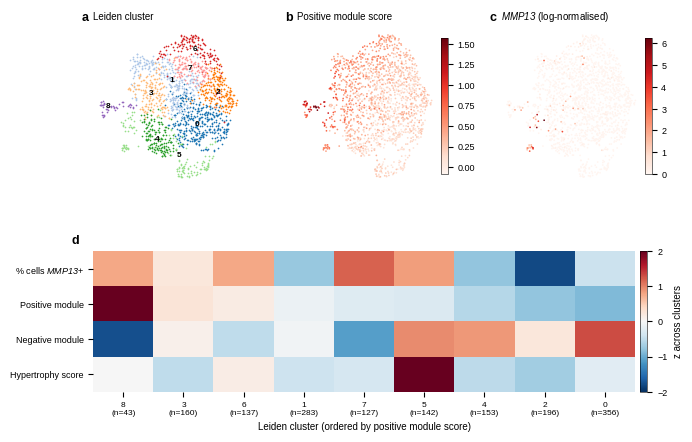

In [7]:
# [module-V3]
import scanpy as sc, anndata
SCDIR = os.path.join(VDIR["cache"], SC["acc"])
def find_sc_inputs(acc):
    gse = GEOparse.get_GEO(geo=acc, destdir=GEO_CACHE, silent=True)
    print("title:", gse.metadata.get("title", [""])[0])
    sup = gse.metadata.get("supplementary_file", [])
    print("supplementary files:", [os.path.basename(f) for f in sup])
    paths = []
    for f in sup:
        if f.lower().endswith("filelist.txt"): continue
        fn = fetch(f, SCDIR); paths.append(fn)
        if fn.lower().endswith(".tar"):
            with tarfile.open(fn) as tf: tf.extractall(os.path.join(SCDIR, "untar"))
    return gse, paths

def load_sc(paths):
    root = os.path.join(SCDIR, "untar")
    h5 = [p for p in paths if p.endswith(".h5")] + ([os.path.join(dp, f) for dp, _, fs in os.walk(root) for f in fs if f.endswith(".h5")] if os.path.isdir(root) else [])
    if h5:
        ads = [sc.read_10x_h5(p) for p in h5]
        for a, p in zip(ads, h5): a.obs["sample"] = os.path.basename(p).split("_")[0]; a.var_names_make_unique()
        return (anndata.concat(ads, join='outer', label='batch', index_unique='-') if len(ads) > 1 else ads[0]), f"10x h5 ({len(h5)} files)"
    mtx = [os.path.join(dp, f) for dp, _, fs in os.walk(SCDIR) for f in fs if re.search(r"matrix\.mtx(\.gz)?$", f)]
    if mtx:
        ads = []
        for m in mtx:
            d = os.path.dirname(m); pre = os.path.basename(m).replace("matrix.mtx.gz", "").replace("matrix.mtx", "")
            a = sc.read_10x_mtx(d, prefix=pre or None, var_names="gene_symbols"); a.obs["sample"] = pre or os.path.basename(d)
            a.var_names_make_unique(); ads.append(a)
        return (anndata.concat(ads, join='outer', label='batch', index_unique='-') if len(ads) > 1 else ads[0]), f"10x mtx ({len(mtx)} samples)"
    tabs = [p for p in paths if re.search(r"\.(txt|csv|tsv)(\.gz)?$", p.lower())] + \
           ([os.path.join(dp, f) for dp, _, fs in os.walk(root) for f in fs if re.search(r"\.(txt|csv|tsv)(\.gz)?$", f.lower())]
            if os.path.isdir(root) else [])
    ads = []
    for p in tabs:
        t = read_table_any(p)
        gcol = next((c for c in t.columns if not pd.api.types.is_numeric_dtype(t[c])), None)
        if gcol is None: continue
        t = t.set_index(gcol).select_dtypes(include=[np.number])
        if t.shape[0] < 1000 or t.shape[1] < 50: continue
        if pd.Index(t.index.astype(str)).isin(D.index).mean() > 0.2:      # genes × cells
            a = sc.AnnData(t.T.values.astype(np.float32), obs=pd.DataFrame(index=t.columns.astype(str)),
                           var=pd.DataFrame(index=t.index.astype(str)))
        else:                                                              # cells × genes
            a = sc.AnnData(t.values.astype(np.float32), obs=pd.DataFrame(index=t.index.astype(str)),
                           var=pd.DataFrame(index=t.columns.astype(str)))
        a.var_names_make_unique(); a.obs["sample"] = os.path.basename(p).split(".")[0]; ads.append(a)
    if ads:
        return (anndata.concat(ads, join='outer', label='batch', index_unique='-') if len(ads) > 1 else ads[0]), f"dense tables ({len(ads)})"
    raise ValueError("no readable single-cell matrix (h5, mtx or dense table) found")

SCRES = None
if SC["use"]:
    try:
        gse_sc, paths = find_sc_inputs(SC["acc"])
        ad, how = load_sc(paths)
        print(f"loaded {ad.n_obs} cells × {ad.n_vars} genes from {how}")
        X = ad.X.max() if not hasattr(ad.X, "toarray") else ad.X.max()
        is_counts = float(X) > 50
        sc.pp.filter_cells(ad, min_genes=200); sc.pp.filter_genes(ad, min_cells=3)
        if is_counts:
            sc.pp.normalize_total(ad, target_sum=1e4); sc.pp.log1p(ad)
        elif float(X) > 20:
            sc.pp.log1p(ad)
        ad.raw = ad
        sc.pp.highly_variable_genes(ad, n_top_genes=2000)
        adh = ad[:, ad.var.highly_variable].copy(); sc.pp.scale(adh, max_value=10)
        sc.tl.pca(adh, random_state=SEED); sc.pp.neighbors(adh, random_state=SEED)
        sc.tl.umap(adh, random_state=SEED); sc.tl.leiden(adh, resolution=0.6, random_state=SEED)
        ad.obs["cluster"] = adh.obs["leiden"]; ad.obsm["X_umap"] = adh.obsm["X_umap"]
        mp = [g for g in MOD_POS if g in ad.raw.var_names]; mn = [g for g in MOD_NEG if g in ad.raw.var_names]
        hy = [g for g in HYPERTROPHY if g in ad.raw.var_names]
        sc.tl.score_genes(ad, mp, score_name="module_pos", random_state=SEED, use_raw=True)
        sc.tl.score_genes(ad, mn, score_name="module_neg", random_state=SEED, use_raw=True)
        sc.tl.score_genes(ad, hy, score_name="hypertrophy", random_state=SEED, use_raw=True)
        mm = ad.raw[:, TARGET].X; mm = mm.toarray().ravel() if hasattr(mm, "toarray") else np.asarray(mm).ravel()
        ad.obs["MMP13"] = mm
        sc.tl.rank_genes_groups(ad, "cluster", method="wilcoxon", use_raw=True)
        top = {c: list(pd.DataFrame(ad.uns["rank_genes_groups"]["names"])[c][:8]) for c in ad.obs.cluster.cat.categories}
        SCRES = ad.obs.groupby("cluster").agg(n_cells=("MMP13", "size"), pct_MMP13=("MMP13", lambda s: 100 * (s > 0).mean()),
                                                mean_MMP13=("MMP13", "mean"), module_pos=("module_pos", "mean"),
                                                module_neg=("module_neg", "mean"), hypertrophy=("hypertrophy", "mean"))
        SCRES["top_markers"] = [", ".join(top[c]) for c in SCRES.index]
        SCRES = SCRES.sort_values("module_pos", ascending=False)
        SCRES.to_csv(os.path.join(VDIR["tables"], "V3_singlecell_clusters.csv"))
        cl_r, cl_p = stats.spearmanr(SCRES.mean_MMP13, SCRES.module_pos) if len(SCRES) >= 5 else (np.nan, np.nan)
        cell_r, cell_p = stats.spearmanr(ad.obs.MMP13, ad.obs.module_pos)
        print(SCRES.round(3).to_string())
        print(f"Across clusters: ρ(MMP13, positive module) = {cl_r:.2f}, P = {cl_p:.3g}; "
              f"across cells: ρ = {cell_r:.2f}, P = {cell_p:.3g} (n = {ad.n_obs})")
        json.dump(dict(acc=SC["acc"], cells=int(ad.n_obs), source=how, cluster_rho=cl_r, cluster_p=cl_p,
                       cell_rho=cell_r, cell_p=cell_p, n_pos_genes=len(mp), n_neg_genes=len(mn)),
                  open(os.path.join(VDIR["tables"], "V3_singlecell_summary.json"), "w"), indent=1)

        fig = plt.figure(figsize=(W2, 120 * MM))
        gsf = fig.add_gridspec(2, 3, height_ratios=[1, 0.9], hspace=0.45, wspace=0.35)
        um = ad.obsm["X_umap"]
        for k, (col, lab, cm) in enumerate([("cluster", "Leiden cluster", None), ("module_pos", "Positive module score", "Reds"),
                                            ("MMP13", f"{it(TARGET)} (log-normalised)", "Reds")]):
            ax = fig.add_subplot(gsf[0, k])
            if col == "cluster":
                cats = ad.obs.cluster.cat.categories; pal = plt.get_cmap("tab20")
                for i, c in enumerate(cats):
                    m_ = (ad.obs.cluster == c).values
                    ax.scatter(um[m_, 0], um[m_, 1], s=1.5, color=pal(i % 20), lw=0, rasterized=True)
                    ax.text(np.median(um[m_, 0]), np.median(um[m_, 1]), c, fontsize=6, ha="center", va="center", fontweight="bold")
            else:
                o = np.argsort(ad.obs[col].values)
                s_ = ax.scatter(um[o, 0], um[o, 1], c=ad.obs[col].values[o], s=1.5, cmap=cm, lw=0, rasterized=True)
                cb = fig.colorbar(s_, ax=ax, fraction=0.045, pad=0.02); cb.outline.set_linewidth(0.4)
            ax.set_xticks([]); ax.set_yticks([]); ax.set_title(lab, fontsize=7, loc="left")
            for sp in ax.spines.values(): sp.set_visible(False)
            ax.text(-0.08, 1.05, "abc"[k], transform=ax.transAxes, fontsize=9, fontweight="bold")
        ax = fig.add_subplot(gsf[1, :])
        S = SCRES[["pct_MMP13", "module_pos", "module_neg", "hypertrophy"]]
        Z = (S - S.mean()) / S.std()
        im = ax.imshow(Z.T.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
        ax.set_yticks(range(4)); ax.set_yticklabels([f"% cells {it(TARGET)}+", "Positive module", "Negative module", "Hypertrophy score"])
        ax.set_xticks(range(len(S))); ax.set_xticklabels([f"{c}\n(n={SCRES.loc[c,'n_cells']})" for c in S.index], fontsize=6)
        ax.set_xlabel("Leiden cluster (ordered by positive module score)")
        cb = fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01); cb.set_label("z across clusters"); cb.outline.set_linewidth(0.4)
        for sp in ax.spines.values(): sp.set_visible(False)
        ax.text(-0.04, 1.05, "d", transform=ax.transAxes, fontsize=9, fontweight="bold")
        save(fig, "FigureV2_singlecell_localisation", SCRES); plt.show()
    except Exception as e:
        print(f"Single-cell module SKIPPED: {type(e).__name__}: {e}")

## 6 · Summary + download

In [8]:
# [step-6-summary]
print("Held-out bulk validation:"); print(V1.round(4).to_string(index=False))
if SCRES is not None:
    print("\nSingle-cell clusters (top 5 by positive module):"); print(SCRES.head(5).round(3).to_string())
zp = f"/content/MMP13OA_validation_{datetime.datetime.now():%Y%m%d_%H%M}.zip"
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
    for k in ["tables", "figs"]:
        for dp, _, fns in os.walk(VDIR[k]):
            for fn in fns:
                full = os.path.join(dp, fn); z.write(full, arcname=os.path.relpath(full, BASE))
shutil.copy(zp, BASE)
try:
    from google.colab import files; files.download(zp)
except Exception:
    pass

Held-out bulk validation:
  dataset    tissue                                                                             status  n_OA  n_control   genes  genome_wide_r  genome_wide_p  n_pos_measured  n_neg_measured  median_rho_pos  median_rho_neg  median_rho_bg  frac_pos_same_sign  frac_neg_same_sign  p_pos_shift  p_neg_shift  rho_MMP13_module_pos  p_MMP13_module_pos  rho_MMP13_module_neg  p_MMP13_module_neg  rho_MMP13_hypertrophy  p_MMP13_hypertrophy                     batches  bc_genome_wide_r  bc_median_rho_pos  bc_median_rho_neg  bc_frac_pos_same_sign  bc_frac_neg_same_sign  bc_p_pos_shift  bc_p_neg_shift  bc_rho_MMP13_module_pos  bc_p_MMP13_module_pos  bc_rho_MMP13_module_neg  bc_p_MMP13_module_neg  log2FC  welch_p  age_control_median  age_OA_median  p_unadjusted  p_age_adjusted  p_age_platform_adjusted  beta_age_platform_adjusted  beta_unadjusted  beta_age_adjusted  n_control_age_overlap
 GSE89408  Synovium skipped: no supplementary table whose columns match the GEO samples — s

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import importlib.metadata as m, sys
print("Python", sys.version.split()[0])
for p in ["pandas","numpy","scipy","statsmodels","scikit-learn","gseapy","GEOparse","scanpy","anndata","mygene","networkx","matplotlib"]:
    try: print(p, m.version(p))
    except Exception: print(p, "yok")

Python 3.13.16
pandas 2.2.3
numpy 2.1.3
scipy 1.16.3
statsmodels 0.15.0
scikit-learn 1.6.1
gseapy yok
GEOparse yok
scanpy yok
anndata yok
mygene yok
networkx 3.7
matplotlib 3.10.0


In [ ]:
!pip -q install gseapy GEOparse scanpy anndata mygene
import importlib.metadata as m, sys
print("Python", sys.version.split()[0])
for p in ["pandas","numpy","scipy","statsmodels","scikit-learn","gseapy","GEOparse","scanpy","anndata","mygene","networkx","matplotlib"]:
    try: print(p, m.version(p))
    except Exception: print(p, "yok")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.7/689.7 kB 28.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 53.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.1/52.1 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 103.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 31.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 67.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 6.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currentl